# 03_downstream_classification_Corrected.ipynb

## METALYX — SimCLR downstream classification with a common official evaluation set

This revised notebook trains the downstream logistic-regression classifier using the 1,440 images in the official training directory and evaluates it on the same 360 images in the official validation directory used by the integration experiment.

**Evaluation protocol**
- SimCLR checkpoint: existing checkpoint, loaded without retraining or overwriting.
- Classifier training: official training directory (expected 1,440 images).
- Final evaluation: official validation directory (expected 360 images).
- The integration notebook should use the same image paths, class mapping, feature preprocessing, and classifier settings for a fair comparison.
- The official validation set is called the *evaluation set* here because it is used for the reported comparison. Do not tune settings against it and then describe it as an untouched test set.

Run all cells from top to bottom in a fresh Colab runtime.


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
train_dataset_path = "/content/drive/MyDrive/NEU-DET/train/images"
eval_dataset_path = "/content/drive/MyDrive/NEU-DET/validation/images"
model_path = "/content/drive/MyDrive/METALYX/models/simclr_resnet18.pth"
output_dir = "/content/drive/MyDrive/METALYX/results"

os.makedirs(output_dir, exist_ok=True)

print("Training dataset:", train_dataset_path)
print("Official evaluation dataset:", eval_dataset_path)
print("Model:", model_path)
print("Results:", output_dir)

if not os.path.isdir(train_dataset_path):
    raise FileNotFoundError(f"Training dataset directory not found: {train_dataset_path}")
if not os.path.isdir(eval_dataset_path):
    raise FileNotFoundError(
        f"Official validation directory not found: {eval_dataset_path}. "
        "Check the folder name in Google Drive (it may be 'validation', 'valid', or another name)."
    )
if not os.path.isfile(model_path):
    raise FileNotFoundError(f"SimCLR checkpoint not found: {model_path}")


Training dataset: /content/drive/MyDrive/NEU-DET/train/images
Official evaluation dataset: /content/drive/MyDrive/NEU-DET/validation/images
Model: /content/drive/MyDrive/METALYX/models/simclr_resnet18.pth
Results: /content/drive/MyDrive/METALYX/results


## Note about cached features

This revised notebook extracts features from the existing checkpoint and saves them to a new, protocol-specific file. It intentionally does not reuse the older feature cache, because that cache may have been generated with a different image set or checkpoint.


In [ ]:
# Do not load the old simclr_features.npy cache here.
# The next cells regenerate features from the checkpoint for both official directories.
print("Feature cache will be regenerated from the selected checkpoint.")


Feature cache will be regenerated from the selected checkpoint.


## Check dataset folders and checkpoint

In [ ]:
print("Training directory exists:", os.path.isdir(train_dataset_path))
print("Evaluation directory exists:", os.path.isdir(eval_dataset_path))
print("Checkpoint exists:", os.path.isfile(model_path))


Training directory exists: True
Evaluation directory exists: True
Checkpoint exists: True


Define the six classes

In [ ]:
class_names = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(class_names)
}

idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

print(class_to_idx)

{'crazing': 0, 'inclusion': 1, 'patches': 2, 'pitted_surface': 3, 'rolled-in_scale': 4, 'scratches': 5}


## Load image paths and labels separately for training and official evaluation

In [ ]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

def collect_paths_and_labels(root_dir, class_names, class_to_idx):
    paths, labels = [], []
    for class_name in class_names:
        class_dir = os.path.join(root_dir, class_name)
        if not os.path.isdir(class_dir):
            raise FileNotFoundError(f"Missing class folder: {class_dir}")
        class_images = sorted(
            os.path.join(class_dir, filename)
            for filename in os.listdir(class_dir)
            if filename.lower().endswith(image_extensions)
        )
        paths.extend(class_images)
        labels.extend([class_to_idx[class_name]] * len(class_images))
    return paths, np.asarray(labels, dtype=np.int64)

train_image_paths, train_labels = collect_paths_and_labels(
    train_dataset_path, class_names, class_to_idx
)
eval_image_paths, eval_labels = collect_paths_and_labels(
    eval_dataset_path, class_names, class_to_idx
)

print("Training images:", len(train_image_paths))
print("Evaluation images:", len(eval_image_paths))
print("Training labels:", train_labels.shape)
print("Evaluation labels:", eval_labels.shape)

# Expected NEU-DET counts: 1,440 training and 360 official validation images.
if len(train_image_paths) != 1440:
    raise ValueError(f"Expected 1440 training images, found {len(train_image_paths)}.")
if len(eval_image_paths) != 360:
    raise ValueError(f"Expected 360 official validation images, found {len(eval_image_paths)}.")

# Ensure no image path is shared between the two directories.
overlap = set(map(os.path.abspath, train_image_paths)) & set(map(os.path.abspath, eval_image_paths))
if overlap:
    raise ValueError(f"Found {len(overlap)} overlapping paths between training and evaluation sets.")
print("Training/evaluation path overlap: 0")


Training images: 1440
Evaluation images: 360
Training labels: (1440,)
Evaluation labels: (360,)
Training/evaluation path overlap: 0


## Verify class distribution in both official directories

In [ ]:
print("Training class distribution:")
for class_id, class_name in enumerate(class_names):
    count = int(np.sum(train_labels == class_id))
    print(f"{class_name:20s}: {count}")

print("\nOfficial evaluation class distribution:")
for class_id, class_name in enumerate(class_names):
    count = int(np.sum(eval_labels == class_id))
    print(f"{class_name:20s}: {count}")


Training class distribution:
crazing             : 240
inclusion           : 240
patches             : 240
pitted_surface      : 240
rolled-in_scale     : 240
scratches           : 240

Official evaluation class distribution:
crazing             : 60
inclusion           : 60
patches             : 60
pitted_surface      : 60
rolled-in_scale     : 60
scratches           : 60


Create feature extraction transform

In [ ]:
feature_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

Define SimCLR model

In [ ]:
class SimCLR(nn.Module):

    def __init__(self, projection_dim=128):

        super(SimCLR, self).__init__()

        self.encoder = models.resnet18(weights=None)

        num_features = self.encoder.fc.in_features

        self.encoder.fc = nn.Identity()

        self.projector = nn.Sequential(
            nn.Linear(num_features, 512),
            nn.ReLU(),
            nn.Linear(512, projection_dim)
        )

    def forward(self, x):

        features = self.encoder(x)

        projections = self.projector(features)

        return features, projections

## Load the existing SimCLR checkpoint (do not retrain or overwrite it)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = SimCLR(projection_dim=128).to(device)
checkpoint = torch.load(model_path, map_location=device)

# Support either a wrapped checkpoint or a raw state_dict, without changing the file.
state_dict = checkpoint.get("model_state_dict", checkpoint) if isinstance(checkpoint, dict) else checkpoint
model.load_state_dict(state_dict, strict=True)
model.eval()

print("Existing SimCLR model loaded successfully with strict=True.")
if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))
    print("Checkpoint epoch metadata:", checkpoint.get("epoch", "not recorded"))
else:
    print("Checkpoint is a raw state_dict; no metadata is available.")


Using device: cuda
Existing SimCLR model loaded successfully with strict=True.
Checkpoint keys: ['model_state_dict']
Checkpoint epoch metadata: not recorded


## Extract 512-D encoder features for both directories

In [ ]:
def extract_features(paths, labels, model, transform, device, split_name):
    extracted_features = []
    kept_labels = []
    kept_paths = []

    model.eval()
    with torch.no_grad():
        for image_path, label in zip(paths, labels):
            image = cv2.imread(image_path)
            if image is None:
                raise RuntimeError(f"Could not read image; refusing to silently misalign labels: {image_path}")

            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image_tensor = transform(image).unsqueeze(0).to(device)
            feature, _ = model(image_tensor)

            extracted_features.append(feature.cpu().numpy().reshape(-1))
            kept_labels.append(int(label))
            kept_paths.append(image_path)

    X = np.asarray(extracted_features, dtype=np.float32)
    y = np.asarray(kept_labels, dtype=np.int64)
    p = np.asarray(kept_paths)

    if len(X) != len(paths):
        raise ValueError(f"{split_name}: extracted {len(X)} features for {len(paths)} paths.")
    if X.ndim != 2 or X.shape[1] != 512:
        raise ValueError(f"{split_name}: expected (N, 512) features, got {X.shape}.")
    if not np.isfinite(X).all():
        raise ValueError(f"{split_name}: feature matrix contains NaN or Inf.")

    print(f"{split_name} feature shape: {X.shape}")
    return X, y, p

X_train, y_train, train_paths_used = extract_features(
    train_image_paths, train_labels, model, feature_transform, device, "Training"
)
X_eval, y_eval, eval_paths_used = extract_features(
    eval_image_paths, eval_labels, model, feature_transform, device, "Official evaluation"
)


Training feature shape: (1440, 512)
Official evaluation feature shape: (360, 512)


## Verify feature quality and image-label alignment

In [ ]:
print("Training dtype:", X_train.dtype, "| finite:", np.isfinite(X_train).all())
print("Evaluation dtype:", X_eval.dtype, "| finite:", np.isfinite(X_eval).all())
print("Training labels aligned:", len(X_train) == len(y_train) == len(train_paths_used))
print("Evaluation labels aligned:", len(X_eval) == len(y_eval) == len(eval_paths_used))


Training dtype: float32 | finite: True
Evaluation dtype: float32 | finite: True
Training labels aligned: True
Evaluation labels aligned: True


## Save features to a new protocol-specific cache (does not overwrite older caches)

In [ ]:
feature_output_path = os.path.join(output_dir, "simclr_features_official_train_eval_v2.npz")
np.savez(
    feature_output_path,
    X_train=X_train,
    y_train=y_train,
    train_image_paths=train_paths_used,
    X_eval=X_eval,
    y_eval=y_eval,
    eval_image_paths=eval_paths_used,
    class_names=np.asarray(class_names),
    checkpoint_path=np.asarray([model_path])
)
print("Saved protocol-specific features to:", feature_output_path)


Saved protocol-specific features to: /content/drive/MyDrive/METALYX/results/simclr_features_official_train_eval_v2.npz


# Downstream classification: train on official training images, evaluate on official validation images

In [ ]:
# Use features extracted in this run, rather than silently loading a stale feature cache.
print("Training feature matrix:", X_train.shape)
print("Evaluation feature matrix:", X_eval.shape)
print("Training labels:", y_train.shape)
print("Evaluation labels:", y_eval.shape)


Training feature matrix: (1440, 512)
Evaluation feature matrix: (360, 512)
Training labels: (1440,)
Evaluation labels: (360,)


In [ ]:
print("Training class distribution:")
for class_id, class_name in enumerate(class_names):
    print(f"{class_name:20s}: {int(np.sum(y_train == class_id))}")

print("\nEvaluation class distribution:")
for class_id, class_name in enumerate(class_names):
    print(f"{class_name:20s}: {int(np.sum(y_eval == class_id))}")


Training class distribution:
crazing             : 240
inclusion           : 240
patches             : 240
pitted_surface      : 240
rolled-in_scale     : 240
scratches           : 240

Evaluation class distribution:
crazing             : 60
inclusion           : 60
patches             : 60
pitted_surface      : 60
rolled-in_scale     : 60
scratches           : 60


## Train downstream logistic regression

In [ ]:
# This protocol uses all official training images for classifier fitting
# and the same 360 official validation images for final comparison with the integration notebook.
# No random split of the official training directory is performed here.
print("Classifier training set:", X_train.shape, y_train.shape)
print("Common evaluation set:", X_eval.shape, y_eval.shape)


Classifier training set: (1440, 512) (1440,)
Common evaluation set: (360, 512) (360,)


## Fit preprocessing and classifier on training data only

In [ ]:
classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])
classifier.fit(X_train, y_train)
print("Downstream classifier trained successfully.")
print("Scaler and logistic regression were fitted on training features only.")


Downstream classifier trained successfully.
Scaler and logistic regression were fitted on training features only.


## Evaluate on the common official validation set

In [ ]:
from sklearn.metrics import accuracy_score

y_eval_pred = classifier.predict(X_eval)
eval_accuracy = accuracy_score(y_eval, y_eval_pred)

print(f"Official validation accuracy: {eval_accuracy:.4f}")
print(f"Official validation accuracy: {eval_accuracy * 100:.2f}%")


Official validation accuracy: 0.9194
Official validation accuracy: 91.94%


## Final evaluation metrics (official validation set; not an independent test set)

In [ ]:
# Compatibility aliases for the remaining reporting/plotting cells.
# All reported final metrics below refer to the same official validation set.
y_test = y_eval
y_test_pred = y_eval_pred
test_accuracy = eval_accuracy

print(f"Official validation accuracy: {test_accuracy:.4f}")
print(f"Official validation accuracy: {test_accuracy * 100:.2f}%")


Official validation accuracy: 0.9194
Official validation accuracy: 91.94%


Classification report

In [ ]:
print(
    classification_report(
        y_eval,
        y_eval_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


                 precision    recall  f1-score   support

        crazing     0.9344    0.9500    0.9421        60
      inclusion     0.9333    0.9333    0.9333        60
        patches     0.9524    1.0000    0.9756        60
 pitted_surface     0.8143    0.9500    0.8769        60
rolled-in_scale     0.9194    0.9500    0.9344        60
      scratches     1.0000    0.7333    0.8462        60

       accuracy                         0.9194       360
      macro avg     0.9256    0.9194    0.9181       360
   weighted avg     0.9256    0.9194    0.9181       360



# visualization

## Calculate overall validation metrics

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

precision = precision_score(y_eval, y_eval_pred, average="weighted", zero_division=0)
recall = recall_score(y_eval, y_eval_pred, average="weighted", zero_division=0)
f1 = f1_score(y_eval, y_eval_pred, average="weighted", zero_division=0)
macro_f1 = f1_score(y_eval, y_eval_pred, average="macro", zero_division=0)

print(f"Official validation accuracy : {eval_accuracy * 100:.2f}%")
print(f"Weighted precision           : {precision * 100:.2f}%")
print(f"Weighted recall              : {recall * 100:.2f}%")
print(f"Weighted F1-score            : {f1 * 100:.2f}%")
print(f"Macro F1-score                : {macro_f1 * 100:.2f}%")


Official validation accuracy : 91.94%
Weighted precision           : 92.56%
Weighted recall              : 91.94%
Weighted F1-score            : 91.81%
Macro F1-score                : 91.81%


# Confusion matrix

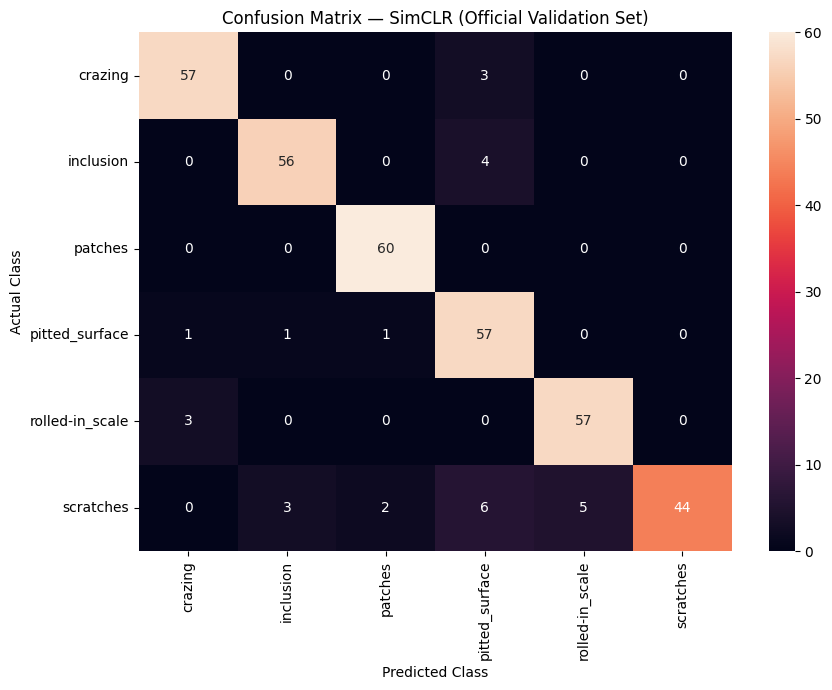

In [ ]:
cm = confusion_matrix(y_eval, y_eval_pred, labels=list(range(len(class_names))))

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix — SimCLR (Official Validation Set)")
plt.tight_layout()
plt.show()


Save the confusion matrix

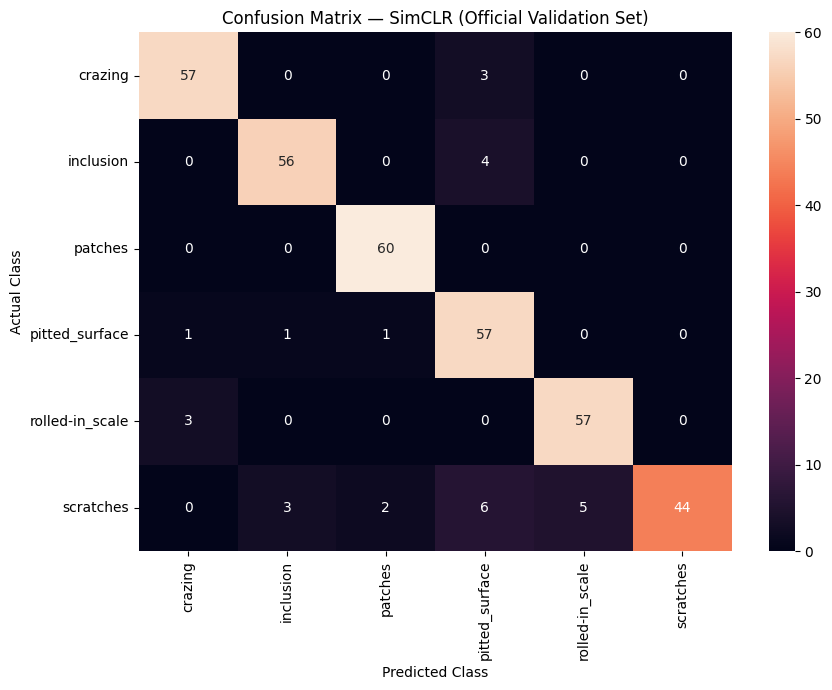

Saved: /content/drive/MyDrive/METALYX/results/simclr_downstream_official_validation_confusion_matrix.png


In [ ]:
cm_path = os.path.join(output_dir, "simclr_downstream_official_validation_confusion_matrix.png")
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix — SimCLR (Official Validation Set)")
plt.tight_layout()
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", cm_path)


# PCA visualization

In [ ]:
# PCA is for visualization only. Fit on the training features, then transform evaluation features.
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
features_pca_train = pca.fit_transform(X_train)
features_pca_eval = pca.transform(X_eval)

print("Training PCA shape:", features_pca_train.shape)
print("Evaluation PCA shape:", features_pca_eval.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())


Training PCA shape: (1440, 2)
Evaluation PCA shape: (360, 2)
Explained variance ratio: [0.2522479  0.19940239]
Total explained variance: 0.4516503


Plot the PCA features

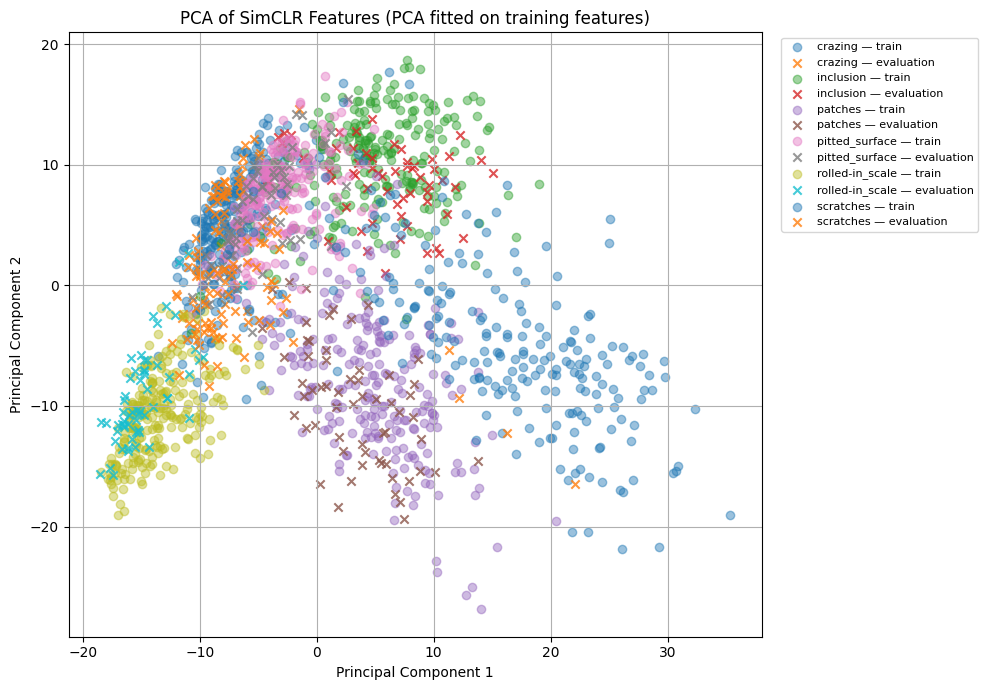

In [ ]:
plt.figure(figsize=(10, 7))
for class_id, class_name in enumerate(class_names):
    train_mask = y_train == class_id
    eval_mask = y_eval == class_id
    plt.scatter(features_pca_train[train_mask, 0], features_pca_train[train_mask, 1],
                label=f"{class_name} — train", alpha=0.45, marker="o")
    plt.scatter(features_pca_eval[eval_mask, 0], features_pca_eval[eval_mask, 1],
                label=f"{class_name} — evaluation", alpha=0.8, marker="x")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of SimCLR Features (PCA fitted on training features)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
pca_path = os.path.join(
    output_dir,
    "simclr_pca_visualization.png"
)

plt.savefig(
    pca_path,
    dpi=300,
    bbox_inches="tight"
)

print("Saved:", pca_path)

Saved: /content/drive/MyDrive/METALYX/results/simclr_pca_visualization.png


<Figure size 640x480 with 0 Axes>

# t-SNE

In [ ]:
# t-SNE is a visualization tool, not a classifier metric.
# Joint embedding is used only to visualize both sets together; do not use it to train the classifier.
from sklearn.manifold import TSNE

all_features_for_viz = np.vstack([X_train, X_eval])
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)
features_tsne = tsne.fit_transform(all_features_for_viz)
print("Joint t-SNE shape:", features_tsne.shape)


Joint t-SNE shape: (1800, 2)


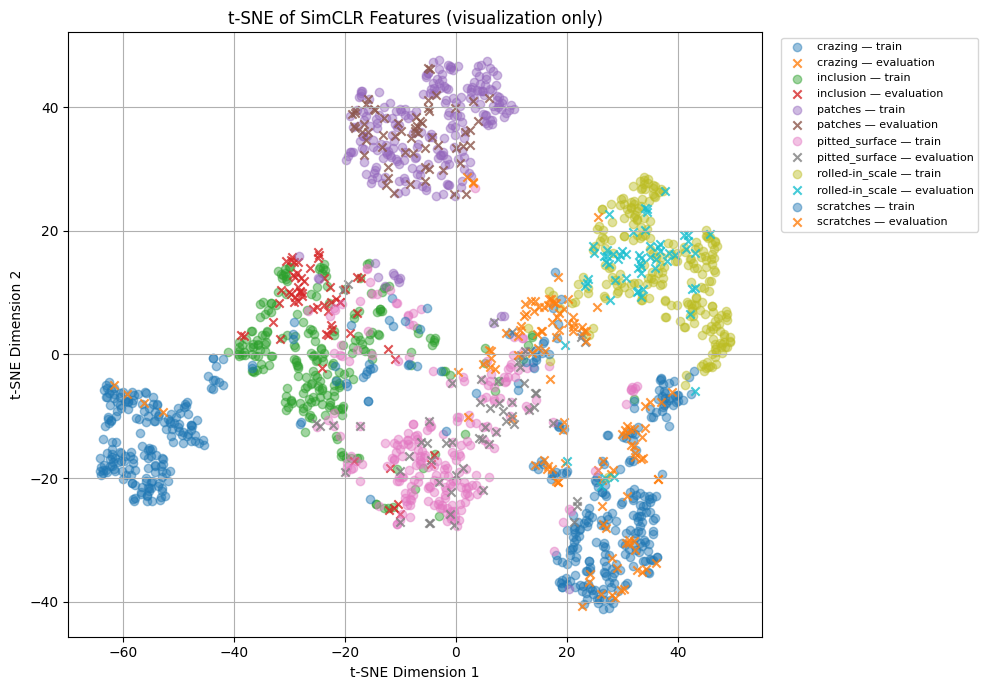

In [ ]:
n_train = len(X_train)
tsne_train = features_tsne[:n_train]
tsne_eval = features_tsne[n_train:]

plt.figure(figsize=(10, 7))
for class_id, class_name in enumerate(class_names):
    train_mask = y_train == class_id
    eval_mask = y_eval == class_id
    plt.scatter(tsne_train[train_mask, 0], tsne_train[train_mask, 1],
                label=f"{class_name} — train", alpha=0.45, marker="o")
    plt.scatter(tsne_eval[eval_mask, 0], tsne_eval[eval_mask, 1],
                label=f"{class_name} — evaluation", alpha=0.8, marker="x")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("t-SNE of SimCLR Features (visualization only)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
tsne_path = os.path.join(output_dir, "simclr_downstream_official_validation_tsne.png")
plt.savefig(tsne_path, dpi=300, bbox_inches="tight")
print("Saved:", tsne_path)


Saved: /content/drive/MyDrive/METALYX/results/simclr_downstream_official_validation_tsne.png


<Figure size 640x480 with 0 Axes>

## Save the fitted classifier and validation metrics

In [ ]:
import joblib

classifier_path = os.path.join(output_dir, "simclr_downstream_classifier_official_protocol_v2.pkl")
joblib.dump(classifier, classifier_path)
print("Classifier saved to:", classifier_path)


Classifier saved to: /content/drive/MyDrive/METALYX/results/simclr_downstream_classifier_official_protocol_v2.pkl


## Save final evaluation metrics

In [ ]:
results = pd.DataFrame({
    "Metric": ["Accuracy", "Weighted precision", "Weighted recall", "Weighted F1-score", "Macro F1-score"],
    "Score": [eval_accuracy, precision, recall, f1, macro_f1]
})
results["Percentage"] = results["Score"] * 100

results_path = os.path.join(output_dir, "simclr_downstream_official_validation_results_v2.csv")
results.to_csv(results_path, index=False)
display(results)
print("Validation results saved to:", results_path)


,Metric,Score,Percentage
0,Accuracy,0.919444,91.944444
1,Weighted precision,0.925630,92.563018
2,Weighted recall,0.919444,91.944444
3,Weighted F1-score,0.918099,91.809917
4,Macro F1-score,0.918099,91.809917


Validation results saved to: /content/drive/MyDrive/METALYX/results/simclr_downstream_official_validation_results_v2.csv


## Save per-class classification report

In [ ]:
report = classification_report(
    y_eval,
    y_eval_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)
report_df = pd.DataFrame(report).transpose()
report_path = os.path.join(output_dir, "simclr_downstream_official_validation_classification_report_v2.csv")
report_df.to_csv(report_path)
print("Classification report saved to:", report_path)


Classification report saved to: /content/drive/MyDrive/METALYX/results/simclr_downstream_official_validation_classification_report_v2.csv
